---
embed-resources: True
format:
    html:
        page-layout: full
        fontsize: 18px

title: 'Parte I | Optimización primal de la red'
author: 'Lorenzo Marquesini'
warning: False
toc: False
---

**Datasets de esta celda:** `destinations.csv`, `origins.csv`, `routes.csv`.

- `destinations.csv` — zonas. `destination` (Capital, Oeste, Este, Costa, Interior); `nominal_demand` 35–50; `shortage_penalty` 60–80; `initial_inventory` 5–8; `storage_capacity` 48–65; `holding_cost` 0.30–0.40; `waste_cost` 0.60–0.80.
- `origins.csv` — centros. `origin` (Norte, Centro, Sur); `supply` 60–95 unidades/semana (oferta reconstruida).
- `routes.csv` — corredores. `route_id` (15 ids, `N-CAP` a `S-INT`); `origin` (Norte, Centro, Sur); `destination` (las cinco zonas); `unit_cost` 3–9; `capacity` 18–42.


In [69]:
import pandas as pd
import ortools
import numpy as np

# Load data
destinations = pd.read_csv("../data/destinations.csv")
origins = pd.read_csv("../data/origins.csv")
routes = pd.read_csv("../data/routes.csv")

## Introducción a los datos

**destinations.csv** — una fila por zona de entrega.

- `destination`: zona. Capital, Oeste, Este, Costa, Interior.
- `nominal_demand`: demanda de la semana típica, unidades logísticas/semana. 35–50.
- `shortage_penalty`: puntos por unidad no atendida. 60–80.
- `initial_inventory`: existencias al inicio del horizonte, unidades. 5–8.
- `storage_capacity`: tope almacenable al cierre de la semana, unidades. 48–65.
- `holding_cost`: puntos por unidad guardada y semana. 0.30–0.40.
- `waste_cost`: puntos por unidad descartada. 0.60–0.80.


**origins.csv** — una fila por centro de consolidación.

- `origin`: centro. Norte, Centro, Sur.
- `supply`: máximo despachable en la semana nominal, unidades logísticas/semana. 60–95. Oferta reconstruida: no vino en los datos de la cátedra.


**routes.csv** — una fila por corredor habilitado.

- `route_id`: identificador del corredor. 15 valores, de `N-CAP` a `S-INT`.
- `origin`: centro de salida. Norte, Centro, Sur.
- `destination`: zona de llegada. Capital, Oeste, Este, Costa, Interior.
- `unit_cost`: puntos logísticos por unidad despachada. 3–9.
- `capacity`: máximo de la ruta antes del estado aleatorio, unidades/semana. 18–42.


## Exploración de datos

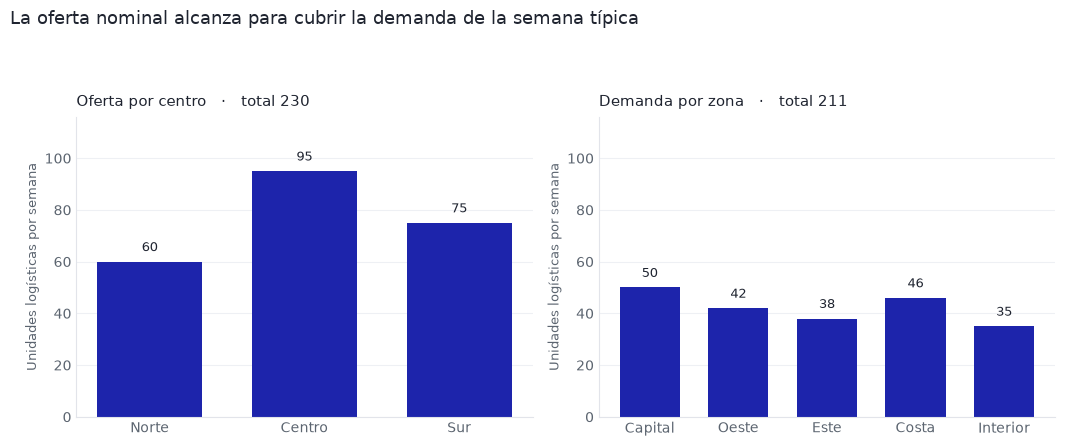

In [70]:
import matplotlib.pyplot as plt

PRIMARY = "#1D24AB"
INK = "#1F2430"
MUTED = "#5C6570"

supply_total = origins["supply"].sum()
demand_total = destinations["nominal_demand"].sum()
ymax = max(origins["supply"].max(), destinations["nominal_demand"].max()) * 1.22

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.5))
fig.suptitle(
    "La oferta nominal alcanza para cubrir la demanda de la semana típica",
    fontsize=13,
    color=INK,
    x=0.0,
    ha="left",
)

panels = [
    (axes[0], origins["origin"], origins["supply"], f"Oferta por centro   ·   total {supply_total:.0f}"),
    (axes[1], destinations["destination"], destinations["nominal_demand"], f"Demanda por zona   ·   total {demand_total:.0f}"),
]
for ax, labels, values, title in panels:
    positions = range(len(labels))
    bars = ax.bar(positions, values, color=PRIMARY, width=0.68, zorder=2)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=8)
    ax.set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
    ax.set_xticks(list(positions), list(labels))
    ax.set_ylim(0, ymax)
    ax.tick_params(axis="both", colors=MUTED, length=0, labelsize=10)
    ax.yaxis.grid(True, color="#EEF0F4", zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E4EA")
    ax.spines["bottom"].set_color("#E2E4EA")
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + ymax * 0.025,
            f"{value:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=INK,
        )

fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

## Matriz de transporte

Las celdas con signo $ son el costo unitario de la ruta. Oferta es lo que puede despachar cada centro y Demanda es lo que necesita cada zona.


In [71]:
from IPython.display import HTML

BLUE = "#1D24AB"
RED = "#C0392B"
INK = "#1F2430"
LINE = "#D5D8E2"

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
cost = routes.pivot(index="origin", columns="destination", values="unit_cost").loc[centers, zones]
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]

def td(text, color=INK, weight="500", italic=False):
    style = (
        f"border:1px solid {LINE}; padding:8px 16px; text-align:center; background:#fff;"
        f"color:{color}; font-weight:{weight};"
    )
    if italic:
        style += "font-style:italic;"
    return f"<td style='{style}'>{text}</td>"

corner = (
    f"<th style='position:relative; min-width:118px; height:56px; border:1px solid {LINE};"
    "background:linear-gradient(to top right,#fff calc(50% - 0.7px),#C5C8D4 calc(50% - 0.7px),"
    f"#C5C8D4 calc(50% + 0.7px),#fff calc(50% + 0.7px));'>"
    f"<span style='position:absolute; top:6px; right:8px; color:{RED}; font-style:italic;'>Hacia</span>"
    f"<span style='position:absolute; bottom:6px; left:8px; color:{BLUE}; font-style:italic;'>Desde</span>"
    "</th>"
)
head = "".join(
    td(zone, color=RED, weight="700", italic=True).replace("td", "th", 2)
    for zone in zones
) + td("Oferta", color=BLUE, weight="700", italic=True).replace("td", "th", 2)

body = []
for origin in centers:
    row = td(origin, color=BLUE, weight="700", italic=True).replace("td", "th", 2)
    row += "".join(td(f"${cost.loc[origin, zone]:.0f}") for zone in zones)
    row += td(f"{supply.loc[origin]:.0f}", color=BLUE, weight="700")
    body.append(f"<tr>{row}</tr>")

demand_row = td("Demanda", color=RED, weight="700", italic=True).replace("td", "th", 2)
demand_row += "".join(td(f"{demand.loc[zone]:.0f}", color=RED, weight="700") for zone in zones)
demand_row += td("")
body.append(f"<tr>{demand_row}</tr>")

table = (
    "<table style='border-collapse:collapse; font-family:sans-serif; font-size:15px;'>"
    f"<thead><tr>{corner}{head}</tr></thead>"
    f"<tbody>{''.join(body)}</tbody></table>"
)
HTML(table)


HaciaDesde,Capital,Oeste,Este,Costa,Interior,Oferta
Norte,$4,$6,$5,$9,$7,60
Centro,$5,$3,$4,$6,$5,95
Sur,$8,$6,$5,$3,$4,75
Demanda,50,42,38,46,35,


## Red de transporte

Cada flecha es una ruta habilitada. El número sobre la flecha es el costo unitario. A la izquierda está la oferta del centro y a la derecha la demanda de la zona.


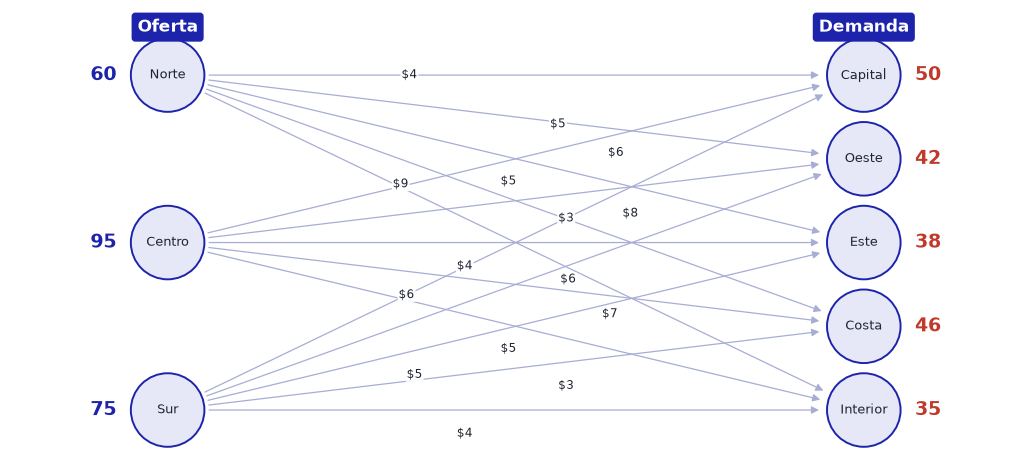

In [72]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

BLUE = "#1D24AB"
RED = "#C0392B"
INK = "#1F2430"
FILL = "#E6E8F7"
EDGE = "#A7ADD4"

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]
cost = routes.set_index(["origin", "destination"])["unit_cost"]

def column_ys(n, top=5.55, bottom=0.45):
    step = (top - bottom) / (n - 1)
    return [top - i * step for i in range(n)]

pos = {name: (1.7, y) for name, y in zip(centers, column_ys(len(centers)))}
pos.update({name: (12.3, y) for name, y in zip(zones, column_ys(len(zones)))})
radius = 0.56

fig, ax = plt.subplots(figsize=(14.6, 5.8))
ax.set_xlim(-0.7, 14.4)
ax.set_ylim(-0.25, 6.55)
ax.set_aspect("equal")
ax.axis("off")

def badge(x, y, text):
    ax.text(
        x, y, text, ha="center", va="center", fontsize=12, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.32,rounding_size=0.18", facecolor=BLUE, edgecolor=BLUE),
        zorder=6,
    )

badge(1.7, 6.28, "Oferta")
badge(12.3, 6.28, "Demanda")

for name, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), radius, facecolor=FILL, edgecolor=BLUE, lw=1.4, zorder=3))
    ax.text(x, y, name, ha="center", va="center", fontsize=9, color=INK, zorder=4)

for name in centers:
    x, y = pos[name]
    ax.text(x - radius - 0.22, y, f"{supply.loc[name]:.0f}", ha="right", va="center", fontsize=14, color=BLUE, fontweight="bold", zorder=4)
for name in zones:
    x, y = pos[name]
    ax.text(x + radius + 0.22, y, f"{demand.loc[name]:.0f}", ha="left", va="center", fontsize=14, color=RED, fontweight="bold", zorder=4)

def arrow_ends(origin, zone):
    x1, y1 = pos[origin]
    x2, y2 = pos[zone]
    dx, dy = x2 - x1, y2 - y1
    dist = math.hypot(dx, dy)
    ux, uy = dx / dist, dy / dist
    start = (x1 + ux * (radius + 0.03), y1 + uy * (radius + 0.03))
    end = (x2 - ux * (radius + 0.08), y2 - uy * (radius + 0.08))
    return start, end, (-uy, ux)

placed = []

def nearest(point):
    if not placed:
        return 99
    return min(math.hypot(point[0] - other[0], point[1] - other[1]) for other in placed)

for origin in centers:
    for zone in zones:
        start, end, (nx, ny) = arrow_ends(origin, zone)
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle="-|>", mutation_scale=11, lw=0.9, color=EDGE, zorder=2,
        ))
        best, best_score = None, -1
        for t in (0.33, 0.42, 0.50, 0.58, 0.67):
            for offset in (0.0, 0.2, -0.2, 0.36, -0.36):
                x = start[0] + t * (end[0] - start[0]) + offset * nx
                y = start[1] + t * (end[1] - start[1]) + offset * ny
                if not (3.0 < x < 11.0 and 0.05 < y < 6.05):
                    continue
                score = nearest((x, y)) - 0.04 * abs(offset)
                if score > best_score:
                    best_score, best = score, (x, y)
        placed.append(best)
        ax.text(
            best[0], best[1], f"${cost.loc[(origin, zone)]:.0f}",
            ha="center", va="center", fontsize=8.5, color=INK, zorder=5,
            bbox=dict(boxstyle="round,pad=0.08", facecolor="white", edgecolor="none", alpha=0.94),
        )

plt.show()


## Variables de decisión

Qué puede decidir la gerencia en la semana nominal: cuánto enviar por cada ruta y cuánto faltante dejar explícito en cada zona.


In [73]:
from IPython.display import HTML

BLUE = "#1D24AB"
NOTE = "#7C4A32"
INK = "#1F2430"

def x(i, j):
    return f"<span style='color:{BLUE};font-weight:650'>x<sub>{i},{j}</sub></span>"

def s(j):
    return f"<span style='color:{BLUE};font-weight:650'>s<sub>{j}</sub></span>"

def line(body, note=""):
    aside = f"<span style='color:{NOTE};font-style:italic;margin-left:16px'>{note}</span>" if note else ""
    return f"<div style='margin:3px 0;line-height:1.55'>{body}{aside}</div>"

def block(parts):
    return (
        "<div style=\"font-family:Georgia,'Times New Roman',serif;font-size:17px;color:"
        + INK + ";padding:4px 0 8px\">"
        + "".join(parts)
        + "</div>"
    )

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
routes_ix = routes.set_index(["origin", "destination"]).sort_index()

parts = []
for origin in centers:
    for zone in zones:
        parts.append(line(
            f"{x(origin, zone)} = unidades enviadas de {origin} a {zone}",
        ))
    parts.append("<div style='height:8px'></div>")
for zone in zones:
    parts.append(line(f"{s(zone)} = unidades no atendidas en {zone}"))

parts.append("<div style='height:14px'></div>")
parts.append(line(f"{x('i', 'j')} = flujo planificado del centro i a la zona j, en unidades logísticas por semana"))
parts.append(line("i = " + ", ".join(centers)))
parts.append(line("j = " + ", ".join(zones)))
parts.append(line(f"{s('j')} = faltante de la zona j, en unidades logísticas por semana"))
HTML(block(parts))


## Función objetivo

Se minimiza el costo de los envíos más la penalización por cada unidad no atendida.


In [74]:
from IPython.display import HTML

BLUE = "#1D24AB"
NOTE = "#7C4A32"
INK = "#1F2430"

def x(i, j):
    return f"<span style='color:{BLUE};font-weight:650'>x<sub>{i},{j}</sub></span>"

def s(j):
    return f"<span style='color:{BLUE};font-weight:650'>s<sub>{j}</sub></span>"

def line(body, note=""):
    aside = f"<span style='color:{NOTE};font-style:italic;margin-left:16px'>{note}</span>" if note else ""
    return f"<div style='margin:3px 0;line-height:1.55'>{body}{aside}</div>"

def block(parts):
    return (
        "<div style=\"font-family:Georgia,'Times New Roman',serif;font-size:17px;color:"
        + INK + ";padding:4px 0 8px\">"
        + "".join(parts)
        + "</div>"
    )

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
cost = routes.set_index(["origin", "destination"])["unit_cost"]
penalty = destinations.set_index("destination")["shortage_penalty"]

parts = [line("<b>Minimizar</b>")]
for origin in centers:
    terms = " + ".join(f"{cost.loc[(origin, zone)]:.0f} {x(origin, zone)}" for zone in zones)
    parts.append(line(terms))
shortage = " + ".join(f"{penalty.loc[zone]:.0f} {s(zone)}" for zone in zones)
parts.append(line("+ " + shortage))
HTML(block(parts))


## Sujeto a

La oferta de cada centro, la capacidad de cada ruta y la demanda de cada zona. El faltante entra en el balance para que la demanda no cubierta quede visible.


In [75]:
from IPython.display import HTML

BLUE = "#1D24AB"
NOTE = "#7C4A32"
INK = "#1F2430"

def x(i, j):
    return f"<span style='color:{BLUE};font-weight:650'>x<sub>{i},{j}</sub></span>"

def s(j):
    return f"<span style='color:{BLUE};font-weight:650'>s<sub>{j}</sub></span>"

def line(body, note=""):
    aside = f"<span style='color:{NOTE};font-style:italic;margin-left:16px'>{note}</span>" if note else ""
    return f"<div style='margin:3px 0;line-height:1.55'>{body}{aside}</div>"

def block(parts):
    return (
        "<div style=\"font-family:Georgia,'Times New Roman',serif;font-size:17px;color:"
        + INK + ";padding:4px 0 8px\">"
        + "".join(parts)
        + "</div>"
    )

centers = origins["origin"].tolist()
zones = destinations["destination"].tolist()
supply = origins.set_index("origin")["supply"]
demand = destinations.set_index("destination")["nominal_demand"]
capacity = routes.set_index(["origin", "destination"])["capacity"]

parts = [line("<b>Oferta de cada centro</b>")]
for origin in centers:
    terms = " + ".join(x(origin, zone) for zone in zones)
    parts.append(line(f"{terms} &le; {supply.loc[origin]:.0f}", f"(oferta de {origin})"))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>Capacidad de cada ruta</b>"))
for origin in centers:
    for zone in zones:
        parts.append(line(
            f"{x(origin, zone)} &le; {capacity.loc[(origin, zone)]:.0f}",
            f"(capacidad {origin}–{zone})",
        ))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>Demanda de cada zona</b>"))
for zone in zones:
    terms = " + ".join(x(origin, zone) for origin in centers)
    parts.append(line(f"{terms} + {s(zone)} = {demand.loc[zone]:.0f}", f"(demanda de {zone})"))

parts.append("<div style='height:12px'></div>")
parts.append(line("<b>No negatividad</b>"))
all_x = ", ".join(x(origin, zone) for origin in centers for zone in zones)
all_s = ", ".join(s(zone) for zone in zones)
parts.append(line(f"{all_x} &ge; 0"))
parts.append(line(f"{all_s} &ge; 0"))
HTML(block(parts))


## Ficha del modelo

**Decisor.** Gerencia logística de Red Federal de Insumos Esenciales.

**Horizonte.** Una semana operativa típica.

**Conjuntos.** Centros \(I=\{\)Norte, Centro, Sur\(\}\). Zonas \(J=\{\)Capital, Oeste, Este, Costa, Interior\(\}\). Rutas \(E\): las 15 de `routes.csv`.

**Datos y unidades.**

- \(a_i\): `origins.supply`, unidades logísticas por semana. Oferta reconstruida: Norte 60, Centro 95, Sur 75. El archivo oficial no fue publicado.
- \(d_j\): `destinations.nominal_demand`, unidades por semana.
- \(u_{ij}\): `routes.capacity`, unidades por semana.
- \(c_{ij}\): `routes.unit_cost`, puntos logísticos por unidad.
- \(p_j\): `destinations.shortage_penalty`, puntos por unidad no atendida. No es un precio de venta.

**Variables.** \(x_{ij}\ge 0\), flujo planificado por la ruta. \(s_j\ge 0\), demanda no atendida en la zona. Ambas son continuas: la unidad logística es divisible.

**Objetivo.** Minimizar \(\sum c_{ij} x_{ij} + \sum p_j s_j\).

**Restricciones.** Lo que sale de cada centro no supera su oferta. Cada ruta no supera su capacidad. En cada zona, lo recibido más el faltante iguala la demanda.

**Supuestos.** El faltante se ve y se penaliza; no se borra de la cuenta. No hay pedidos pendientes dentro de esta semana. No se exige despacho en pallets enteros.

**Tres pruebas a mano.** Un corredor Norte–Capital, costo 4 y penalización 80.

1. Factible: oferta 10, capacidad 10, demanda 6. Debe enviar 6, sin faltante, a costo 24.
2. Infactible: capacidad 3, demanda 6 y sin variable de faltante. No hay forma de cumplir la igualdad.
3. Borde: oferta, capacidad y demanda iguales a 6. El envío llena las dos cotas y el faltante queda en cero.


In [76]:
from ortools.linear_solver import pywraplp

def caso_mini(oferta, capacidad, demanda, costo, penalizacion, con_faltante):
    modelo = pywraplp.Solver.CreateSolver("GLOP")
    flujo = modelo.NumVar(0, modelo.infinity(), "x")
    faltante = modelo.NumVar(0, modelo.infinity(), "s") if con_faltante else 0
    modelo.Add(flujo <= oferta, "oferta")
    modelo.Add(flujo <= capacidad, "capacidad")
    modelo.Add(flujo + faltante == demanda, "demanda")
    modelo.Minimize(costo * flujo + penalizacion * faltante)
    estado = modelo.Solve()
    return estado, flujo, faltante, modelo

estado, flujo, faltante, modelo = caso_mini(10, 10, 6, 4, 80, True)
assert estado == pywraplp.Solver.OPTIMAL
assert abs(flujo.solution_value() - 6) < 1e-7
assert abs(faltante.solution_value()) < 1e-7
assert abs(modelo.Objective().Value() - 24) < 1e-7
print("Factible: OPTIMAL, x = 6, s = 0, costo = 24")

estado, flujo, faltante, modelo = caso_mini(10, 3, 6, 4, 80, False)
assert estado == pywraplp.Solver.INFEASIBLE
print("Infactible: INFEASIBLE, sin faltante y con capacidad 3 frente a demanda 6")

estado, flujo, faltante, modelo = caso_mini(6, 6, 6, 4, 80, True)
assert estado == pywraplp.Solver.OPTIMAL
assert abs(flujo.solution_value() - 6) < 1e-7
assert abs(faltante.solution_value()) < 1e-7
assert abs(modelo.Objective().Value() - 24) < 1e-7
print("Borde: OPTIMAL, x = 6 llena oferta y capacidad, s = 0, costo = 24")


Factible: OPTIMAL, x = 6, s = 0, costo = 24
Infactible: INFEASIBLE, sin faltante y con capacidad 3 frente a demanda 6
Borde: OPTIMAL, x = 6 llena oferta y capacidad, s = 0, costo = 24


## Planteo con OR-TOOLS

El mismo modelo, planteado con GLOP como en los laboratorios: una variable con nombre por ruta y por faltante, cada restricción con nombre, y el estado del solver antes de leer la solución.


In [77]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("GLOP")
assert solver is not None, "No se pudo crear el solver GLOP"

# Variables
x = {}
for row in routes.itertuples(index=False):
    x[row.route_id] = solver.NumVar(0, solver.infinity(), f"x_{row.route_id}")

s = {}
for zone in destinations["destination"]:
    s[zone] = solver.NumVar(0, solver.infinity(), f"s_{zone}")

# Restricciones
oferta = origins.set_index("origin")["supply"]
for origin in origins["origin"]:
    salidas = routes.loc[routes["origin"] == origin, "route_id"]
    solver.Add(
        sum(x[rid] for rid in salidas) <= float(oferta.loc[origin]),
        f"oferta_{origin}",
    )

for row in routes.itertuples(index=False):
    solver.Add(x[row.route_id] <= row.capacity, f"capacidad_{row.route_id}")

demanda = destinations.set_index("destination")["nominal_demand"]
penalizacion = destinations.set_index("destination")["shortage_penalty"]
for zone in destinations["destination"]:
    entradas = routes.loc[routes["destination"] == zone, "route_id"]
    solver.Add(
        sum(x[rid] for rid in entradas) + s[zone] == float(demanda.loc[zone]),
        f"demanda_{zone}",
    )

# Función objetivo
costo_envio = sum(row.unit_cost * x[row.route_id] for row in routes.itertuples(index=False))
costo_faltante = sum(float(penalizacion.loc[zone]) * s[zone] for zone in s)
solver.Minimize(costo_envio + costo_faltante)

status = solver.Solve()
assert status == pywraplp.Solver.OPTIMAL, f"Estado inesperado: {status}"

flujos = routes[["route_id", "origin", "destination", "unit_cost", "capacity"]].copy()
flujos["flujo"] = [x[rid].solution_value() for rid in flujos["route_id"]]
flujos["aporte"] = flujos["flujo"] * flujos["unit_cost"]

faltantes = destinations[["destination", "nominal_demand", "shortage_penalty"]].copy()
faltantes["faltante"] = [s[zone].solution_value() for zone in faltantes["destination"]]

costo_tabla = faltantes["faltante"].mul(faltantes["shortage_penalty"]).sum() + flujos["aporte"].sum()
assert abs(costo_tabla - solver.Objective().Value()) < 1e-7

print("Estado: OPTIMAL")
print("Costo mínimo =", round(solver.Objective().Value(), 2))
display(flujos.round(4))
display(faltantes.round(4))


Estado: OPTIMAL
Costo mínimo = 818.0


,route_id,origin,destination,unit_cost,capacity,flujo,aporte
0,N-CAP,Norte,Capital,4.0,42.0,42.0,168.0
1,N-OES,Norte,Oeste,6.0,28.0,0.0,0.0
2,N-EST,Norte,Este,5.0,30.0,4.0,20.0
3,N-COS,Norte,Costa,9.0,18.0,0.0,0.0
4,N-INT,Norte,Interior,7.0,26.0,0.0,0.0
5,C-CAP,Centro,Capital,5.0,35.0,8.0,40.0
6,C-OES,Centro,Oeste,3.0,35.0,35.0,105.0
7,C-EST,Centro,Este,4.0,34.0,34.0,136.0
8,C-COS,Centro,Costa,6.0,32.0,8.0,48.0
9,C-INT,Centro,Interior,5.0,28.0,5.0,25.0


,destination,nominal_demand,shortage_penalty,faltante
0,Capital,50.0,80.0,0.0
1,Oeste,42.0,70.0,0.0
2,Este,38.0,65.0,0.0
3,Costa,46.0,75.0,0.0
4,Interior,35.0,60.0,0.0


## Certificado de optimalidad

GLOP declara el plan nominal óptimo solo si el objetivo primal coincide con el objetivo dual y se cumple la holgura complementaria: una variable entre cotas tiene costo reducido nulo, y una restricción con holgura tiene dual nulo.


In [78]:
BASE = {
    solver.FREE: "libre",
    solver.AT_LOWER_BOUND: "cota inferior",
    solver.AT_UPPER_BOUND: "cota superior",
    solver.FIXED_VALUE: "fijada",
    solver.BASIC: "básica",
}
inf = solver.infinity()
dual_obj = 0.0
for restriccion in solver.constraints():
    lb, ub, dual = restriccion.lb(), restriccion.ub(), restriccion.dual_value()
    if ub < inf and lb > -inf and abs(lb - ub) <= 1e-9:
        dual_obj += dual * ub
    else:
        if ub < inf:
            dual_obj += dual * ub
        if lb > -inf:
            dual_obj += dual * lb
for variable in solver.variables():
    if variable.lb() > -inf:
        dual_obj += variable.reduced_cost() * variable.lb()
    if variable.ub() < inf:
        dual_obj += variable.reduced_cost() * variable.ub()

primal = solver.Objective().Value()
assert solver.VerifySolution(1e-7, False)
assert abs(primal - dual_obj) <= 1e-7

filas_var = []
for variable in solver.variables():
    valor = variable.solution_value()
    rc = variable.reduced_cost()
    if valor > 1e-7 and abs(rc) > 1e-7:
        raise AssertionError(f"{variable.name()} está entre cotas y tiene costo reducido")
    if valor <= 1e-7 and rc < -1e-7:
        raise AssertionError(f"{variable.name()} está en cero con costo reducido negativo")
    filas_var.append({
        "variable": variable.name(),
        "valor": valor,
        "costo_reducido": rc,
        "base": BASE.get(variable.basis_status(), str(variable.basis_status())),
    })

uso = flujos.groupby("origin")["flujo"].sum()
recibido = flujos.groupby("destination")["flujo"].sum()
faltante_zona = faltantes.set_index("destination")["faltante"]
holgura = {}
for origin in origins["origin"]:
    holgura[f"oferta_{origin}"] = float(oferta.loc[origin] - uso.loc[origin])
for row in routes.itertuples(index=False):
    holgura[f"capacidad_{row.route_id}"] = float(row.capacity - flujos.set_index("route_id").loc[row.route_id, "flujo"])
for zone in destinations["destination"]:
    holgura[f"demanda_{zone}"] = float(recibido.loc[zone] + faltante_zona.loc[zone] - demanda.loc[zone])

filas_rest = []
for restriccion in solver.constraints():
    slack = holgura[restriccion.name()]
    dual = restriccion.dual_value()
    if abs(slack) > 1e-7 and abs(dual) > 1e-7:
        raise AssertionError(f"{restriccion.name()} tiene holgura y dual distintos de cero")
    filas_rest.append({
        "restriccion": restriccion.name(),
        "dual": dual,
        "holgura": slack,
        "base": BASE.get(restriccion.basis_status(), str(restriccion.basis_status())),
    })

print("Estado: OPTIMAL")
print("Verificación interna de GLOP: True")
print(f"Objetivo primal = {primal:.4f}")
print(f"Objetivo dual   = {dual_obj:.4f}")
print(f"Diferencia      = {abs(primal - dual_obj):.2e}")
print(f"Iteraciones     = {solver.iterations()}")
print(f"Tiempo (ms)     = {solver.wall_time()}")
print("Holgura complementaria: cumple")
display(pd.DataFrame(filas_var).round(4))
display(pd.DataFrame(filas_rest).round(4))


Estado: OPTIMAL
Verificación interna de GLOP: True
Objetivo primal = 818.0000
Objetivo dual   = 818.0000
Diferencia      = 0.00e+00
Iteraciones     = 11
Tiempo (ms)     = 21
Holgura complementaria: cumple


,variable,valor,costo_reducido,base
0,x_N-CAP,42.0,0.0,básica
1,x_N-OES,0.0,0.0,cota inferior
2,x_N-EST,4.0,0.0,básica
3,x_N-COS,0.0,3.0,cota inferior
4,x_N-INT,0.0,2.0,cota inferior
5,x_C-CAP,8.0,0.0,básica
6,x_C-OES,35.0,0.0,básica
7,x_C-EST,34.0,0.0,básica
8,x_C-COS,8.0,0.0,básica
9,x_C-INT,5.0,0.0,básica


,restriccion,dual,holgura,base
0,oferta_Norte,0.0,14.0,básica
1,oferta_Centro,0.0,5.0,básica
2,oferta_Sur,0.0,0.0,cota superior
3,capacidad_N-CAP,-1.0,0.0,cota superior
4,capacidad_N-OES,0.0,28.0,básica
5,capacidad_N-EST,0.0,26.0,básica
6,capacidad_N-COS,0.0,18.0,básica
7,capacidad_N-INT,0.0,26.0,básica
8,capacidad_C-CAP,0.0,27.0,básica
9,capacidad_C-OES,-3.0,0.0,cota superior


## Verificación independiente

El costo, el balance de cada zona, el uso y la holgura de cada centro, la holgura de cada ruta y la no negatividad se recalculan desde los flujos. No se vuelven a leer los campos del solver. La tolerancia es \(10^{-7}\).


In [79]:
import math
from ortools.linear_solver import pywraplp

TOL = 1e-7

def techo(factor, serie):
    return pd.Series(
        {clave: float(math.ceil(round(factor * float(valor), 8))) for clave, valor in serie.items()}
    )

def resolver(demanda_obj, oferta_obj, capacidad_obj):
    modelo = pywraplp.Solver.CreateSolver("GLOP")
    assert modelo is not None, "No se pudo crear el solver GLOP"
    x = {
        row.route_id: modelo.NumVar(0, modelo.infinity(), f"x_{row.route_id}")
        for row in routes.itertuples(index=False)
    }
    s = {
        zone: modelo.NumVar(0, modelo.infinity(), f"s_{zone}")
        for zone in destinations["destination"]
    }
    penalizacion = destinations.set_index("destination")["shortage_penalty"]
    for origin in origins["origin"]:
        salidas = routes.loc[routes["origin"] == origin, "route_id"]
        modelo.Add(sum(x[rid] for rid in salidas) <= float(oferta_obj.loc[origin]), f"oferta_{origin}")
    for row in routes.itertuples(index=False):
        modelo.Add(x[row.route_id] <= float(capacidad_obj.loc[row.route_id]), f"capacidad_{row.route_id}")
    for zone in destinations["destination"]:
        entradas = routes.loc[routes["destination"] == zone, "route_id"]
        modelo.Add(sum(x[rid] for rid in entradas) + s[zone] == float(demanda_obj.loc[zone]), f"demanda_{zone}")
    modelo.Minimize(
        sum(row.unit_cost * x[row.route_id] for row in routes.itertuples(index=False))
        + sum(float(penalizacion.loc[zone]) * s[zone] for zone in s)
    )
    status = modelo.Solve()
    assert status == pywraplp.Solver.OPTIMAL, f"Estado inesperado: {status}"
    flujos_esc = routes[["route_id", "origin", "destination", "unit_cost"]].copy()
    flujos_esc["capacity"] = flujos_esc["route_id"].map(capacidad_obj).astype(float)
    flujos_esc["flujo"] = [x[rid].solution_value() for rid in flujos_esc["route_id"]]
    faltantes_esc = destinations[["destination", "shortage_penalty"]].copy()
    faltantes_esc["demanda"] = faltantes_esc["destination"].map(demanda_obj).astype(float)
    faltantes_esc["faltante"] = [s[zone].solution_value() for zone in faltantes_esc["destination"]]
    return modelo.Objective().Value(), flujos_esc, faltantes_esc

def verificar(flujos_esc, faltantes_esc, oferta_obj, tol=TOL):
    objetivo = float(
        (flujos_esc["flujo"] * flujos_esc["unit_cost"]).sum()
        + (faltantes_esc["faltante"] * faltantes_esc["shortage_penalty"]).sum()
    )
    recibido = flujos_esc.groupby("destination")["flujo"].sum()
    balance = faltantes_esc.copy()
    balance["recibido"] = balance["destination"].map(recibido).fillna(0)
    balance["residuo"] = balance["recibido"] + balance["faltante"] - balance["demanda"]
    uso = flujos_esc.groupby("origin")["flujo"].sum()
    centros = pd.DataFrame({
        "oferta": oferta_obj.astype(float),
        "uso": uso.reindex(oferta_obj.index).fillna(0.0),
    })
    centros["holgura"] = centros["oferta"] - centros["uso"]
    rutas = flujos_esc[["route_id", "flujo", "capacity"]].copy()
    rutas["holgura"] = rutas["capacity"] - rutas["flujo"]
    assert balance["residuo"].abs().max() <= tol
    assert centros["holgura"].min() >= -tol
    assert rutas["holgura"].min() >= -tol
    assert flujos_esc["flujo"].min() >= -tol
    assert faltantes_esc["faltante"].min() >= -tol
    return objetivo, balance, centros, rutas

demanda_nominal = destinations.set_index("destination")["nominal_demand"]
oferta_nominal = origins.set_index("origin")["supply"]
capacidad_nominal = routes.set_index("route_id")["capacity"]
costo_nominal = float(solver.Objective().Value())
flujos_nominales = flujos.copy()
faltante_nominal = float(faltantes["faltante"].sum())

objetivo, balance, centros, rutas = verificar(
    flujos.assign(demanda=flujos["destination"].map(demanda_nominal)),
    faltantes.assign(demanda=faltantes["nominal_demand"]),
    oferta_nominal,
)
print("Objetivo recalculado =", round(objetivo, 4))
print("Coincide con el solver:", abs(objetivo - costo_nominal) <= TOL)
display(balance.round(4))
display(centros.round(4))
display(rutas.round(4))


Objetivo recalculado = 818.0
Coincide con el solver: True


,destination,nominal_demand,shortage_penalty,faltante,demanda,recibido,residuo
0,Capital,50.0,80.0,0.0,50.0,50.0,-0.0
1,Oeste,42.0,70.0,0.0,42.0,42.0,0.0
2,Este,38.0,65.0,0.0,38.0,38.0,0.0
3,Costa,46.0,75.0,0.0,46.0,46.0,-0.0
4,Interior,35.0,60.0,0.0,35.0,35.0,0.0


,oferta,uso,holgura
origin,,,
Norte,60.0,46.0,14.0
Centro,95.0,90.0,5.0
Sur,75.0,75.0,0.0


,route_id,flujo,capacity,holgura
0,N-CAP,42.0,42.0,0.0
1,N-OES,0.0,28.0,28.0
2,N-EST,4.0,30.0,26.0
3,N-COS,0.0,18.0,18.0
4,N-INT,0.0,26.0,26.0
5,C-CAP,8.0,35.0,27.0
6,C-OES,35.0,35.0,0.0
7,C-EST,34.0,34.0,0.0
8,C-COS,8.0,32.0,24.0
9,C-INT,5.0,28.0,23.0


## Escenario S1 — demanda +10 %

Cada demanda nominal se multiplica por 1,10 y se redondea hacia arriba: \(d_j^{S1}=\lceil 1{,}10\, d_j\rceil\). Oferta y capacidades quedan igual.


In [80]:
demanda_s1 = techo(1.10, demanda_nominal)
costo_s1, flujos_s1, faltantes_s1 = resolver(demanda_s1, oferta_nominal, capacidad_nominal)
verificar(flujos_s1, faltantes_s1, oferta_nominal)
print("Estado: OPTIMAL")
print("Demanda modificada:", demanda_s1.to_dict())
print(f"Costo = {costo_s1:.2f}    diferencia vs nominal = {costo_s1 - costo_nominal:.2f}")
print(f"Faltante = {faltantes_s1['faltante'].sum():.2f}    diferencia vs nominal = {faltantes_s1['faltante'].sum() - faltante_nominal:.2f}")
comparacion = flujos_s1[["route_id", "origin", "destination", "flujo"]].merge(
    flujos_nominales[["route_id", "flujo"]], on="route_id", suffixes=("", "_nominal")
)
comparacion["diferencia"] = comparacion["flujo"] - comparacion["flujo_nominal"]
display(comparacion.round(4))
display(faltantes_s1.round(4))


Estado: OPTIMAL
Demanda modificada: {'Capital': 55.0, 'Oeste': 47.0, 'Este': 42.0, 'Costa': 51.0, 'Interior': 39.0}
Costo = 1168.00    diferencia vs nominal = 350.00
Faltante = 4.00    diferencia vs nominal = 4.00


,route_id,origin,destination,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,0.0
1,N-OES,Norte,Oeste,5.0,0.0,5.0
2,N-EST,Norte,Este,13.0,4.0,9.0
3,N-COS,Norte,Costa,0.0,0.0,0.0
4,N-INT,Norte,Interior,0.0,0.0,0.0
5,C-CAP,Centro,Capital,13.0,8.0,5.0
6,C-OES,Centro,Oeste,35.0,35.0,0.0
7,C-EST,Centro,Este,29.0,34.0,-5.0
8,C-COS,Centro,Costa,13.0,8.0,5.0
9,C-INT,Centro,Interior,5.0,5.0,0.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,55.0,0.0
1,Oeste,70.0,47.0,0.0
2,Este,65.0,42.0,0.0
3,Costa,75.0,51.0,0.0
4,Interior,60.0,39.0,4.0


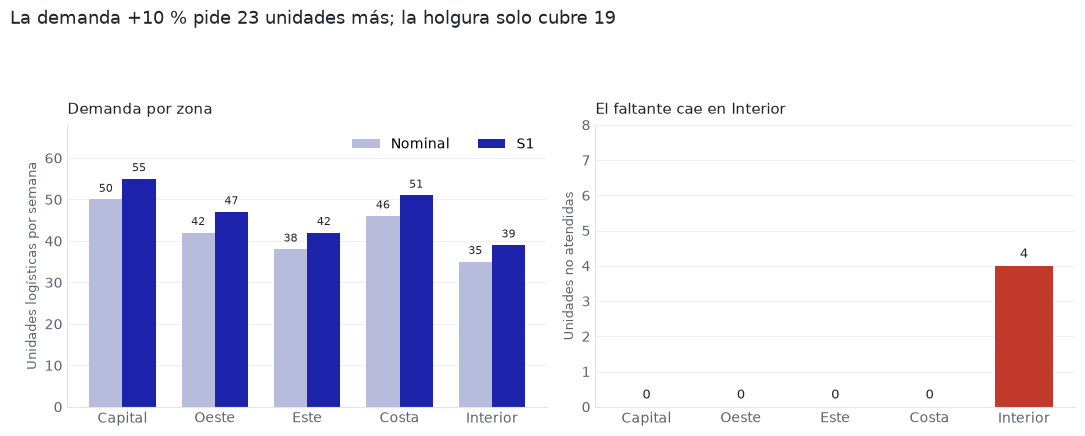

In [81]:
import matplotlib.pyplot as plt

PRIMARY = "#1D24AB"
NOMINAL = "#B7BCDC"
ALERT = "#C0392B"
INK = "#1F2430"
MUTED = "#5C6570"
CERO = "#E4E6F2"

def etiqueta(valor):
    return f"{valor:.0f}" if abs(valor - round(valor)) < 1e-6 else f"{valor:.1f}".replace(".", ",")

def limpiar(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E4EA")
    ax.spines["bottom"].set_color("#E2E4EA")
    ax.tick_params(length=0, colors=MUTED, labelsize=10)
    ax.yaxis.grid(True, color="#EEF0F4")
    ax.set_axisbelow(True)

zonas = list(destinations["destination"])
faltante_s1 = faltantes_s1.set_index("destination")["faltante"]

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
fig.suptitle(
    "La demanda +10 % pide 23 unidades más; la holgura solo cubre 19",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(zonas))
barras_nominal = axes[0].bar(
    [i - 0.18 for i in eje], [demanda_nominal[z] for z in zonas],
    width=0.36, color=NOMINAL, label="Nominal", zorder=2,
)
barras_s1 = axes[0].bar(
    [i + 0.18 for i in eje], [demanda_s1[z] for z in zonas],
    width=0.36, color=PRIMARY, label="S1", zorder=2,
)
axes[0].set_xticks(list(eje), zonas)
axes[0].set_ylim(0, 68)
axes[0].set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
axes[0].set_title("Demanda por zona", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s1):
    axes[0].text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.2,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=8, color=INK,
    )
axes[0].legend(frameon=False, ncol=2, loc="upper right")
limpiar(axes[0])

faltante = [float(faltante_s1.loc[z]) for z in zonas]
barras = axes[1].bar(
    zonas, faltante, width=0.62, zorder=2,
    color=[ALERT if zona == "Interior" else CERO for zona in zonas],
)
axes[1].set_ylim(0, 8)
axes[1].set_ylabel("Unidades no atendidas", color=MUTED, fontsize=9)
axes[1].set_title("El faltante cae en Interior", loc="left", color=INK, fontsize=11, pad=8)
for barra, valor in zip(barras, faltante):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2, valor + 0.15,
        etiqueta(valor), ha="center", va="bottom", fontsize=9, color=INK,
    )
limpiar(axes[1])
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()


## Escenario S2 — capacidad Centro–Oeste al 70 %

La capacidad de C-OES pasa a \(0{,}70\, u_{C-OES}\), sin redondeo. Demanda y oferta quedan igual.


In [82]:
capacidad_s2 = capacidad_nominal.copy()
capacidad_s2.loc["C-OES"] = 0.70 * float(capacidad_nominal.loc["C-OES"])
costo_s2, flujos_s2, faltantes_s2 = resolver(demanda_nominal, oferta_nominal, capacidad_s2)
verificar(flujos_s2, faltantes_s2, oferta_nominal)
print("Estado: OPTIMAL")
print(f"Capacidad C-OES = {capacidad_s2.loc['C-OES']:.2f}")
print(f"Costo = {costo_s2:.2f}    diferencia vs nominal = {costo_s2 - costo_nominal:.2f}")
print(f"Faltante = {faltantes_s2['faltante'].sum():.2f}    diferencia vs nominal = {faltantes_s2['faltante'].sum() - faltante_nominal:.2f}")
comparacion = flujos_s2[["route_id", "origin", "destination", "flujo", "capacity"]].merge(
    flujos_nominales[["route_id", "flujo"]], on="route_id", suffixes=("", "_nominal")
)
comparacion["diferencia"] = comparacion["flujo"] - comparacion["flujo_nominal"]
display(comparacion.round(4))
display(faltantes_s2.round(4))


Estado: OPTIMAL
Capacidad C-OES = 24.50
Costo = 849.50    diferencia vs nominal = 31.50
Faltante = 0.00    diferencia vs nominal = 0.00


,route_id,origin,destination,flujo,capacity,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,10.5,28.0,0.0,10.5
2,N-EST,Norte,Este,4.0,30.0,4.0,0.0
3,N-COS,Norte,Costa,0.0,18.0,0.0,0.0
4,N-INT,Norte,Interior,0.0,26.0,0.0,0.0
5,C-CAP,Centro,Capital,8.0,35.0,8.0,0.0
6,C-OES,Centro,Oeste,24.5,24.5,35.0,-10.5
7,C-EST,Centro,Este,34.0,34.0,34.0,0.0
8,C-COS,Centro,Costa,8.0,32.0,8.0,0.0
9,C-INT,Centro,Interior,5.0,28.0,5.0,0.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,50.0,0.0
1,Oeste,70.0,42.0,0.0
2,Este,65.0,38.0,0.0
3,Costa,75.0,46.0,0.0
4,Interior,60.0,35.0,0.0


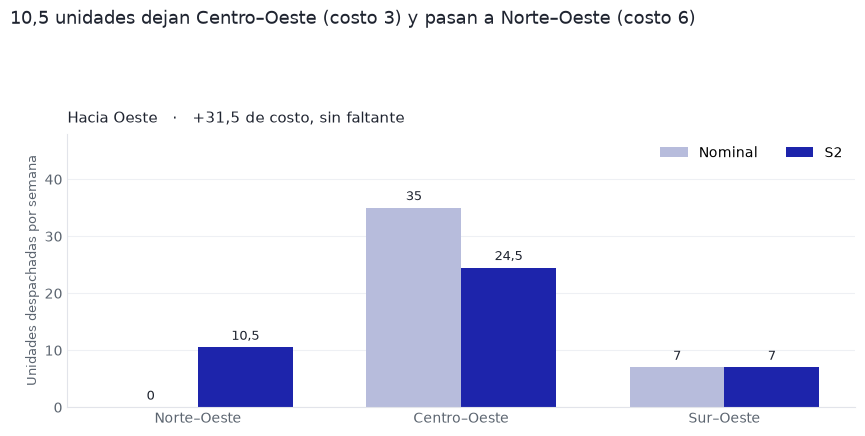

In [83]:
import matplotlib.pyplot as plt

PRIMARY = "#1D24AB"
NOMINAL = "#B7BCDC"
ALERT = "#C0392B"
INK = "#1F2430"
MUTED = "#5C6570"
CERO = "#E4E6F2"

def etiqueta(valor):
    return f"{valor:.0f}" if abs(valor - round(valor)) < 1e-6 else f"{valor:.1f}".replace(".", ",")

def limpiar(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E4EA")
    ax.spines["bottom"].set_color("#E2E4EA")
    ax.tick_params(length=0, colors=MUTED, labelsize=10)
    ax.yaxis.grid(True, color="#EEF0F4")
    ax.set_axisbelow(True)

rutas_oeste = ["N-OES", "C-OES", "S-OES"]
nombres = ["Norte–Oeste", "Centro–Oeste", "Sur–Oeste"]
flujo_nominal = flujos_nominales.set_index("route_id").loc[rutas_oeste, "flujo"]
flujo_s2 = flujos_s2.set_index("route_id").loc[rutas_oeste, "flujo"]

fig, ax = plt.subplots(figsize=(8.6, 4.4))
fig.suptitle(
    "10,5 unidades dejan Centro–Oeste (costo 3) y pasan a Norte–Oeste (costo 6)",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(nombres))
barras_nominal = ax.bar(
    [i - 0.18 for i in eje], flujo_nominal, width=0.36, color=NOMINAL, label="Nominal", zorder=2,
)
barras_s2 = ax.bar(
    [i + 0.18 for i in eje], flujo_s2, width=0.36, color=PRIMARY, label="S2", zorder=2,
)
ax.set_xticks(list(eje), nombres)
ax.set_ylim(0, 48)
ax.set_ylabel("Unidades despachadas por semana", color=MUTED, fontsize=9)
ax.set_title("Hacia Oeste   ·   +31,5 de costo, sin faltante", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s2):
    ax.text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.8,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=9, color=INK,
    )
ax.legend(frameon=False, ncol=2, loc="upper right")
limpiar(ax)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()



## Escenario S3 — oferta al 90 %

La oferta de cada centro pasa a \(0{,}90\, a_i\), sin redondeo. Demanda y capacidades quedan igual.


In [84]:
oferta_s3 = oferta_nominal * 0.90
costo_s3, flujos_s3, faltantes_s3 = resolver(demanda_nominal, oferta_s3, capacidad_nominal)
verificar(flujos_s3, faltantes_s3, oferta_s3)
print("Estado: OPTIMAL")
print("Oferta modificada:", {k: round(float(v), 2) for k, v in oferta_s3.items()})
print(f"Costo = {costo_s3:.2f}    diferencia vs nominal = {costo_s3 - costo_nominal:.2f}")
print(f"Faltante = {faltantes_s3['faltante'].sum():.2f}    diferencia vs nominal = {faltantes_s3['faltante'].sum() - faltante_nominal:.2f}")
comparacion = flujos_s3[["route_id", "origin", "destination", "flujo"]].merge(
    flujos_nominales[["route_id", "flujo"]], on="route_id", suffixes=("", "_nominal")
)
comparacion["diferencia"] = comparacion["flujo"] - comparacion["flujo_nominal"]
display(comparacion.round(4))
display(faltantes_s3.round(4))


Estado: OPTIMAL
Oferta modificada: {'Norte': 54.0, 'Centro': 85.5, 'Sur': 67.5}
Costo = 1039.50    diferencia vs nominal = 221.50
Faltante = 4.00    diferencia vs nominal = 4.00


,route_id,origin,destination,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,42.0,42.0,0.0
1,N-OES,Norte,Oeste,7.0,0.0,7.0
2,N-EST,Norte,Este,5.0,4.0,1.0
3,N-COS,Norte,Costa,0.0,0.0,0.0
4,N-INT,Norte,Interior,0.0,0.0,0.0
5,C-CAP,Centro,Capital,8.0,8.0,0.0
6,C-OES,Centro,Oeste,35.0,35.0,0.0
7,C-EST,Centro,Este,33.0,34.0,-1.0
8,C-COS,Centro,Costa,8.0,8.0,0.0
9,C-INT,Centro,Interior,1.5,5.0,-3.5


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,50.0,0.0
1,Oeste,70.0,42.0,0.0
2,Este,65.0,38.0,0.0
3,Costa,75.0,46.0,0.0
4,Interior,60.0,35.0,4.0


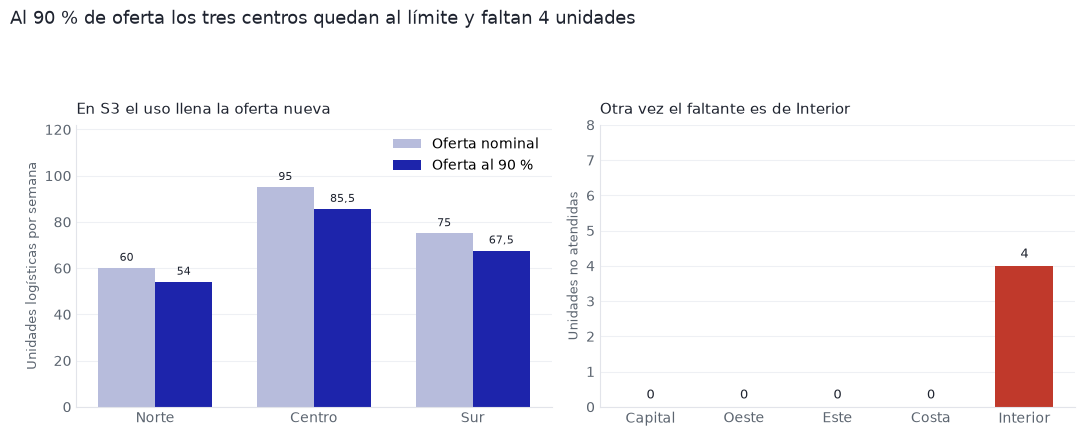

In [85]:
import matplotlib.pyplot as plt

PRIMARY = "#1D24AB"
NOMINAL = "#B7BCDC"
ALERT = "#C0392B"
INK = "#1F2430"
MUTED = "#5C6570"
CERO = "#E4E6F2"

def etiqueta(valor):
    return f"{valor:.0f}" if abs(valor - round(valor)) < 1e-6 else f"{valor:.1f}".replace(".", ",")

def limpiar(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E4EA")
    ax.spines["bottom"].set_color("#E2E4EA")
    ax.tick_params(length=0, colors=MUTED, labelsize=10)
    ax.yaxis.grid(True, color="#EEF0F4")
    ax.set_axisbelow(True)

centros = list(origins["origin"])
uso_s3 = flujos_s3.groupby("origin")["flujo"].sum()
faltante_s3 = faltantes_s3.set_index("destination")["faltante"]

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
fig.suptitle(
    "Al 90 % de oferta los tres centros quedan al límite y faltan 4 unidades",
    fontsize=13, color=INK, x=0, ha="left",
)
eje = range(len(centros))
barras_nominal = axes[0].bar(
    [i - 0.18 for i in eje], [oferta_nominal[c] for c in centros],
    width=0.36, color=NOMINAL, label="Oferta nominal", zorder=2,
)
barras_s3 = axes[0].bar(
    [i + 0.18 for i in eje], [oferta_s3[c] for c in centros],
    width=0.36, color=PRIMARY, label="Oferta al 90 %", zorder=2,
)
axes[0].set_xticks(list(eje), centros)
axes[0].set_ylim(0, 122)
axes[0].set_ylabel("Unidades logísticas por semana", color=MUTED, fontsize=9)
axes[0].set_title("En S3 el uso llena la oferta nueva", loc="left", color=INK, fontsize=11, pad=8)
for barra in list(barras_nominal) + list(barras_s3):
    axes[0].text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 2,
        etiqueta(barra.get_height()), ha="center", va="bottom", fontsize=8, color=INK,
    )
axes[0].legend(frameon=False, loc="upper right")
limpiar(axes[0])

zonas = list(destinations["destination"])
faltante = [float(faltante_s3.loc[z]) for z in zonas]
barras = axes[1].bar(
    zonas, faltante, width=0.62, zorder=2,
    color=[ALERT if valor > 0 else CERO for valor in faltante],
)
axes[1].set_ylim(0, 8)
axes[1].set_ylabel("Unidades no atendidas", color=MUTED, fontsize=9)
axes[1].set_title("Otra vez el faltante es de Interior", loc="left", color=INK, fontsize=11, pad=8)
for barra, valor in zip(barras, faltante):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2, valor + 0.15,
        etiqueta(valor), ha="center", va="bottom", fontsize=9, color=INK,
    )
limpiar(axes[1])
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()



## Plan de resguardo

Se resuelve el mismo modelo con una demanda de diseño cinco por ciento mayor, redondeada hacia arriba: \(d_j^{res}=\lceil 1{,}05\, d_j\rceil\). Este plan no reemplaza los tres escenarios. Queda fijo para compararlo, en la Parte II, contra el plan nominal sobre los mismos futuros.


In [86]:
demanda_resguardo = techo(1.05, demanda_nominal)
costo_resguardo, flujos_resguardo, faltantes_resguardo = resolver(
    demanda_resguardo, oferta_nominal, capacidad_nominal
)
verificar(flujos_resguardo, faltantes_resguardo, oferta_nominal)
print("Estado: OPTIMAL")
print("Demanda de diseño:", demanda_resguardo.to_dict())
print(f"Costo = {costo_resguardo:.2f}    diferencia vs nominal = {costo_resguardo - costo_nominal:.2f}")
print(f"Faltante = {faltantes_resguardo['faltante'].sum():.2f}    diferencia vs nominal = {faltantes_resguardo['faltante'].sum() - faltante_nominal:.2f}")
comparacion = flujos_resguardo[["route_id", "origin", "destination", "unit_cost", "capacity", "flujo"]].merge(
    flujos_nominales[["route_id", "flujo"]], on="route_id", suffixes=("", "_nominal")
)
comparacion["diferencia"] = comparacion["flujo"] - comparacion["flujo_nominal"]
display(comparacion.round(4))
display(faltantes_resguardo.round(4))


Estado: OPTIMAL
Demanda de diseño: {'Capital': 53.0, 'Oeste': 45.0, 'Este': 40.0, 'Costa': 49.0, 'Interior': 37.0}
Costo = 892.00    diferencia vs nominal = 74.00
Faltante = 0.00    diferencia vs nominal = 0.00


,route_id,origin,destination,unit_cost,capacity,flujo,flujo_nominal,diferencia
0,N-CAP,Norte,Capital,4.0,42.0,42.0,42.0,0.0
1,N-OES,Norte,Oeste,6.0,28.0,3.0,0.0,3.0
2,N-EST,Norte,Este,5.0,30.0,9.0,4.0,5.0
3,N-COS,Norte,Costa,9.0,18.0,0.0,0.0,0.0
4,N-INT,Norte,Interior,7.0,26.0,0.0,0.0,0.0
5,C-CAP,Centro,Capital,5.0,35.0,11.0,8.0,3.0
6,C-OES,Centro,Oeste,3.0,35.0,35.0,35.0,0.0
7,C-EST,Centro,Este,4.0,34.0,31.0,34.0,-3.0
8,C-COS,Centro,Costa,6.0,32.0,11.0,8.0,3.0
9,C-INT,Centro,Interior,5.0,28.0,7.0,5.0,2.0


,destination,shortage_penalty,demanda,faltante
0,Capital,80.0,53.0,0.0
1,Oeste,70.0,45.0,0.0
2,Este,65.0,40.0,0.0
3,Costa,75.0,49.0,0.0
4,Interior,60.0,37.0,0.0


## Fuentes

Formulación de un problema de transporte como programa lineal:

[Transportation Problem - LP Formulation](https://www.youtube.com/watch?v=WZIyL6pcItY), Joshua Emmanuel.
